# 01 - Data Collection

**Goal:** collect daily data from 2010 to Sep 2026 for predicting the 1-month, 5-year and 30-year US Treasury yields.

The data comes from two sources:

| Source | What we take from it |
|---|---|
| **Yahoo Finance** (`yfinance`) | Treasury yield indices (^IRX, ^FVX, ^TNX, ^TYX) and market indicators: VIX, S&P 500, Brent crude, gold, US dollar index |
| **FRED** (Federal Reserve Economic Data) | Full Treasury yield curve (1M to 30Y), federal debt holdings, Baa corporate spread |

Yahoo Finance only has four Treasury yields (13-week, 5Y, 10Y, 30Y). It has no 1-month yield, which is one of our three targets, and no debt or credit spread data. So the yield curve is taken from FRED (same as the original case study), and Yahoo is used for the market indicators and to cross-check the yields that both sources have.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from src import config, data, plots

plots.setup()
pd.set_option("display.width", 140)

## 1. Connecting to Yahoo Finance

A quick look at what `yfinance` returns, using the 10-year Treasury yield index (^TNX).

In [2]:
tnx = yf.Ticker("^TNX")
tnx.history(start="2026-09-21", end="2026-10-01")[["Open", "High", "Low", "Close"]]

,Open,High,Low,Close
Date,,,,
2026-09-21 00:00:00-05:00,4.953,4.976,4.951,4.963
2026-09-22 00:00:00-05:00,4.929,4.982,4.926,4.968
2026-09-23 00:00:00-05:00,4.990,5.135,4.984,5.114
2026-09-24 00:00:00-05:00,5.121,5.181,5.087,5.162
2026-09-25 00:00:00-05:00,5.186,5.230,5.162,5.184
2026-09-28 00:00:00-05:00,5.209,5.274,5.205,5.240
2026-09-29 00:00:00-05:00,5.213,5.293,5.213,5.255
2026-09-30 00:00:00-05:00,5.243,5.306,5.205,5.293


The `Close` column is the yield in percent, so ^TNX = 4.1 means a 10-year yield of 4.1%. Only the daily close is used in this project.

## 2. Downloading all the data

`data.download_all()` downloads every series and saves it as its own CSV in `data/raw/`. Later notebooks only read these files, so the results don't change if Yahoo or FRED revise their data. The data is frozen at **30 September 2026**.

FRED is downloaded from its public CSV link, which doesn't need an API key.

In [3]:
data.download_all()

FRED  DGS1MO     4690 values  2008-01-02 to 2026-09-30


FRED  DGS3MO     4690 values  2008-01-02 to 2026-09-30


FRED  DGS1       4690 values  2008-01-02 to 2026-09-30


FRED  DGS2       4690 values  2008-01-02 to 2026-09-30


FRED  DGS5       4690 values  2008-01-02 to 2026-09-30


...

Yahoo ^VIX       4718 values  2008-01-02 to 2026-09-30


Yahoo ^GSPC      4716 values  2008-01-02 to 2026-09-30


Yahoo BZ=F       4664 values  2008-01-02 to 2026-09-30


Yahoo GC=F       4716 values  2008-01-02 to 2026-09-30


Yahoo DX-Y.NYB   4717 values  2008-01-02 to 2026-09-30


In [4]:
fred, yahoo = data.load_raw()

fred_summary = pd.DataFrame({
    "values": {s: fred[s].notna().sum() for s in config.FRED_SERIES},
    "first date": {s: fred[s].dropna().index.min().date() for s in config.FRED_SERIES},
    "last date": {s: fred[s].dropna().index.max().date() for s in config.FRED_SERIES},
})
fred_summary["frequency"] = ["daily"] * 9 + ["weekly", "quarterly", "quarterly", "quarterly"]
fred_summary

,values,first date,last date,frequency
DGS1MO,4690,2008-01-02,2026-09-30,daily
DGS3MO,4690,2008-01-02,2026-09-30,daily
DGS1,4690,2008-01-02,2026-09-30,daily
DGS2,4690,2008-01-02,2026-09-30,daily
DGS5,4690,2008-01-02,2026-09-30,daily
DGS7,4690,2008-01-02,2026-09-30,daily
DGS10,4690,2008-01-02,2026-09-30,daily
DGS30,4690,2008-01-02,2026-09-30,daily
BAA10Y,4685,2008-01-02,2026-09-30,daily
TREAST,979,2008-01-02,2026-09-30,weekly


| FRED code | Meaning |
|---|---|
| DGS1MO ... DGS30 | Treasury constant maturity yields, 1 month to 30 years (%) |
| BAA10Y | Moody's Baa corporate bond yield minus the 10-year Treasury yield (%) |
| TREAST | Treasury securities held by the Federal Reserve ($ millions) |
| FYGFDPUN | Federal debt held by the public ($ millions) |
| FDHBFIN | Federal debt held by foreign and international investors (**$ billions**) |
| GFDEBTN | Total public debt ($ millions) |

The series come in three different frequencies (daily, weekly and quarterly), so they have to be lined up before they can be used together.

## 3. Building one daily table

Steps inside `data.build_dataset()`:

1. **Calendar:** use the days on which Treasury yields were published (bond market trading days). Holidays come as blank rows in FRED and are dropped.
2. **Publication delay:** FRED dates each quarterly debt value at the *start* of the quarter, but the number is only published months later. In October 2026 the latest total-debt value on FRED was still the one dated 1 April 2026. If we forward filled from the label date, the model would "know" debt numbers before they were released (look-ahead bias). So the quarterly values are moved forward by 2 quarters (3 quarters for foreign holdings, which come out even later). The weekly Fed holdings are moved forward by 2 days, because the Wednesday number is released on Thursday afternoon.
3. **Forward fill:** weekly, quarterly and Yahoo values are carried forward until a new value is available.
4. **Debt shares**, the same features as the case study:
   - `GOV_PCT` = Fed holdings / total debt
   - `HOM_PCT` = debt held by the public / total debt
   - `FOR_PCT` = foreign holdings / total debt (FDHBFIN is converted from billions to millions first)

In [5]:
df = data.build_dataset(fred, yahoo)
print("Shape:", df.shape)
print("From", df.index.min().date(), "to", df.index.max().date())
df.head()

Shape: (4189, 21)
From 2010-01-04 to 2026-09-30


,DGS1MO,DGS3MO,DGS1,DGS2,DGS5,DGS7,DGS10,DGS30,BAA10Y,GOV_PCT,...,FOR_PCT,YH_3M,YH_5Y,YH_10Y,YH_30Y,VIX,SP500,BRENT,GOLD,DXY
date,,,,,,,,,,,,,,,,,,,,,
2010-01-04,0.05,0.08,0.45,1.09,2.65,3.36,3.85,4.65,2.54,6.520556,...,29.058354,0.055,2.652,3.841,4.660,20.040001,1132.989990,80.120003,1117.699951,77.529999
2010-01-05,0.03,0.07,0.41,1.01,2.56,3.28,3.77,4.59,2.53,6.520556,...,29.058354,0.060,2.558,3.755,4.593,19.350000,1136.520020,80.589996,1118.099976,77.620003
2010-01-06,0.03,0.06,0.40,1.01,2.60,3.33,3.85,4.70,2.49,6.520556,...,29.058354,0.045,2.573,3.808,4.671,19.160000,1137.140015,81.889999,1135.900024,77.489998
2010-01-07,0.02,0.05,0.40,1.03,2.62,3.33,3.85,4.69,2.48,6.520556,...,29.058354,0.045,2.600,3.822,4.689,19.059999,1141.689941,81.510002,1133.099976,77.910004
2010-01-08,0.02,0.05,0.37,0.96,2.57,3.31,3.83,4.70,2.49,6.520623,...,29.058354,0.040,2.566,3.808,4.695,18.129999,1144.979980,81.370003,1138.199951,77.470001


Example of the publication delay for total public debt (GFDEBTN):

In [6]:
quarterly = fred["GFDEBTN"].dropna().loc["2024-10-01":"2025-07-01"]
lag = config.PUBLICATION_LAG_QUARTERS["GFDEBTN"]
pd.DataFrame({"FRED date": quarterly.index.date,
              "total debt ($ trillion)": (quarterly.values / 1e6).round(2),
              "used in our data from": (quarterly.index + pd.DateOffset(months=3 * lag)).date})

,FRED date,total debt ($ trillion),used in our data from
0,2024-10-01,36.22,2025-04-01
1,2025-01-01,36.21,2025-07-01
2,2025-04-01,36.21,2025-10-01
3,2025-07-01,37.64,2026-01-01


## 4. Sanity checks

### 4.1 Missing values

In [7]:
df.isna().sum()

DGS1MO     0
DGS3MO     0
DGS1       0
DGS2       0
DGS5       0
DGS7       0
DGS10      0
DGS30      0
BAA10Y     0
GOV_PCT    0
HOM_PCT    0
FOR_PCT    0
YH_3M      0
YH_5Y      0
YH_10Y     0
YH_30Y     0
VIX        0
SP500      0
BRENT      0
GOLD       0
DXY        0
dtype: int64

In [8]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
DGS1MO,4189.0,1.49,1.90,0.00,0.05,0.23,2.44,6.02
DGS3MO,4189.0,1.54,1.90,0.00,0.06,0.30,2.49,5.63
DGS1,4189.0,1.63,1.77,0.04,0.17,0.60,3.11,5.49
DGS2,4189.0,1.73,1.59,0.09,0.38,0.91,3.14,5.19
DGS5,4189.0,2.15,1.25,0.19,1.23,1.75,3.07,5.09
DGS7,4189.0,2.44,1.13,0.36,1.55,2.17,3.28,5.19
DGS10,4189.0,2.69,1.05,0.52,1.89,2.53,3.55,5.29
DGS30,4189.0,3.32,0.96,0.99,2.73,3.12,4.14,5.64
BAA10Y,4189.0,2.33,0.54,1.36,1.87,2.25,2.73,4.31
GOV_PCT,4189.0,12.95,3.24,6.08,11.17,12.42,13.93,20.26


### 4.2 Cross-checking Yahoo against FRED

Three tenors are in both sources: 5Y, 10Y and 30Y. Yahoo's ^IRX is the 13-week bill, which is close to FRED's 3-month yield but not the same instrument. If the two sources agree, we can trust the data.

In [9]:
pairs = {"YH_3M": "DGS3MO", "YH_5Y": "DGS5", "YH_10Y": "DGS10", "YH_30Y": "DGS30"}
rows = []
for yh, fr in pairs.items():
    diff_bp = (df[yh] - df[fr]) * 100          # 1 basis point = 0.01%
    rows.append({"Yahoo": yh, "FRED": fr,
                 "correlation": df[yh].corr(df[fr]),
                 "mean abs diff (bp)": diff_bp.abs().mean(),
                 "max abs diff (bp)": diff_bp.abs().max()})
pd.DataFrame(rows).round(4)

,Yahoo,FRED,correlation,mean abs diff (bp),max abs diff (bp)
0,YH_3M,DGS3MO,0.9999,6.3728,40.7
1,YH_5Y,DGS5,1.0000,0.8661,13.3
2,YH_10Y,DGS10,0.9999,0.9879,10.5
3,YH_30Y,DGS30,1.0000,0.6471,12.7


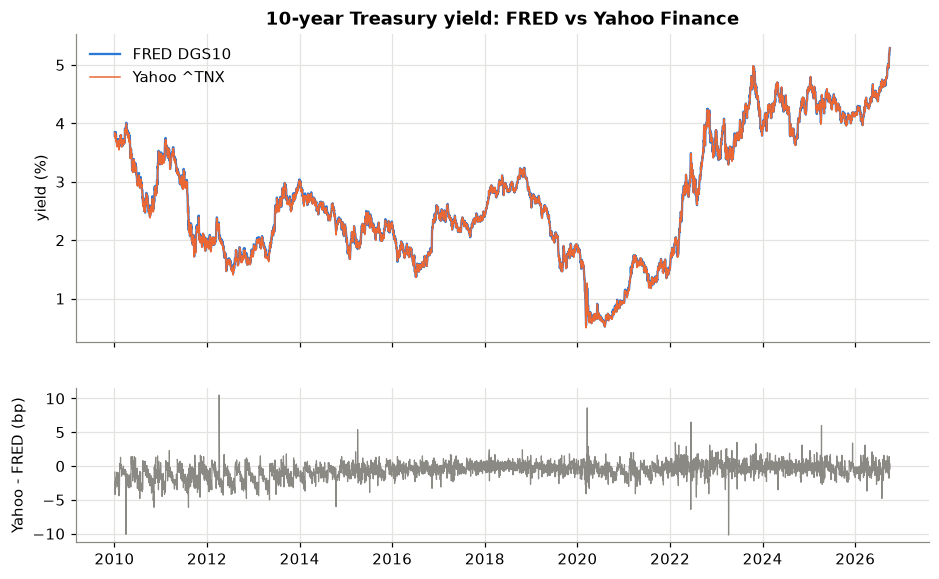

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[2, 1])
axes[0].plot(df.index, df["DGS10"], color=plots.BLUE, label="FRED DGS10")
axes[0].plot(df.index, df["YH_10Y"], color=plots.ORANGE, linewidth=1, label="Yahoo ^TNX")
axes[0].set_ylabel("yield (%)")
axes[0].set_title("10-year Treasury yield: FRED vs Yahoo Finance")
axes[0].legend()
axes[1].plot(df.index, (df["YH_10Y"] - df["DGS10"]) * 100, color=plots.GREY, linewidth=0.8)
axes[1].set_ylabel("Yahoo - FRED (bp)")
plots.save(fig, "01_fred_vs_yahoo_10y")
plt.show()

**Observations**
- For 5Y, 10Y and 30Y the two sources almost match: correlation of 0.9999 or more, and the average gap is under 1 basis point (0.01%).
- The small spikes of 5-13 bp happen on very volatile days. Yahoo's index closes at a slightly different time of day from the Treasury's official end-of-day curve, which FRED uses.
- ^IRX differs more (about 6 bp on average) because it's a different instrument: a 13-week bill quoted as a discount rate, while FRED's DGS3MO is a 3-month bond-equivalent yield.
- So the data is reliable, and using FRED for the curve and Yahoo for the market indicators is safe.
- The 10-year yield ended September 2026 at its highest level of the whole period. Models trained on older data will have to handle yields they have never seen before (see notebook 02).

## 5. Saving the dataset

In [11]:
config.PROCESSED_FILE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(config.PROCESSED_FILE)
print("Saved", config.PROCESSED_FILE.name, df.shape)

Saved dataset.csv (4189, 21)
